# Mean Waveforms

Mean waveforms (solid lines) and SEM (shaded areas) for cholinergic, glutamatergic, and GABAergic neurons in the VEH and COC groups.

In [2]:
from pathlib import Path
import json

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.figsize": (10, 6), "font.size": 18})
mpl.rcParams["axes.spines.right"] = False
mpl.rcParams["axes.spines.top"] = False

## Data locations

The waveform files used here are collected beforehand with `scripts/collect_s6_waveforms.py`. The notebook reads only the centralized directory.

In [3]:
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

METADATA_PATH = PROJECT_ROOT / "data" / "LDT_tagged" / "LDT_tagged.json"
WAVEFORM_DIR = PROJECT_ROOT / "data" / "waveforms" / "S6"

if not METADATA_PATH.is_file():
    raise FileNotFoundError(f"Metadata not found: {METADATA_PATH}")
if not WAVEFORM_DIR.is_dir():
    raise FileNotFoundError(
        f"Centralized waveforms not found: {WAVEFORM_DIR}. "
        "Run: python scripts/collect_s6_waveforms.py --copy"
    )

with METADATA_PATH.open(encoding="utf-8") as stream:
    tagged_units = json.load(stream)

vehicle_units = tagged_units["V_dados"]
cocaine_units = tagged_units["C_dados"]

## Apply the original unit exclusions

These exclusions are retained exactly from the original notebook.

In [4]:
excluded_vehicle_units = {
    "CHAT": {"LDT_VEH31": [171], "LDT_VEH315": [123]},
    "Vglut": {"LDT_VEH45": [343], "LDT_VEH46": [4, 24, 44, 45]},
    "Vgat": {"LDT_VEH57": [242], "LDT_VEH58": [18, 33]},
}

excluded_cocaine_units = {
    "CHAT": {"LDT_COCA35": [93], "LDT_COC36": [36]},
    "Vglut": {"LDT_COC44": [6]},
    "Vgat": {"LDT_COC56": [223]},
}

def remove_excluded_units(unit_dictionary, exclusions):
    for cell_type, animals in exclusions.items():
        for animal, excluded_clusters in animals.items():
            if animal in unit_dictionary.get(cell_type, {}):
                unit_dictionary[cell_type][animal] = [
                    cluster
                    for cluster in unit_dictionary[cell_type][animal]
                    if cluster not in excluded_clusters
                ]

remove_excluded_units(vehicle_units, excluded_vehicle_units)
remove_excluded_units(cocaine_units, excluded_cocaine_units)

for cell_type in vehicle_units:
    vehicle_count = sum(len(clusters) for clusters in vehicle_units[cell_type].values())
    cocaine_count = sum(len(clusters) for clusters in cocaine_units[cell_type].values())
    print(f"{cell_type}: VEH={vehicle_count}, COC={cocaine_count}")

CHAT: VEH=15, COC=23
Vglut: VEH=57, COC=52
Vgat: VEH=26, COC=26


## Load centralized waveforms and plot group summaries

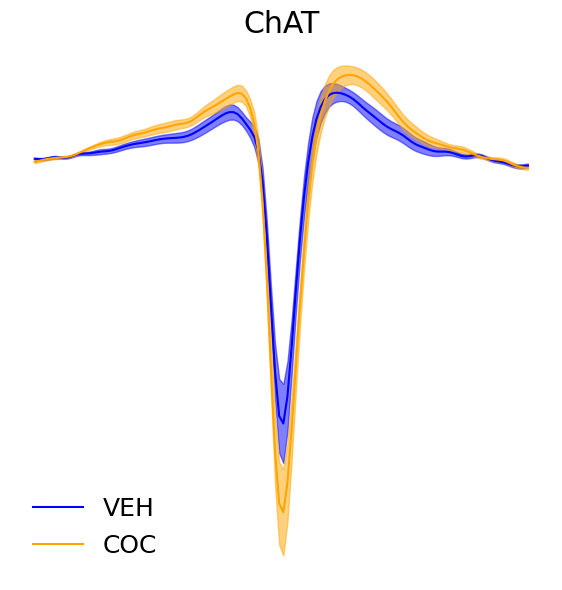

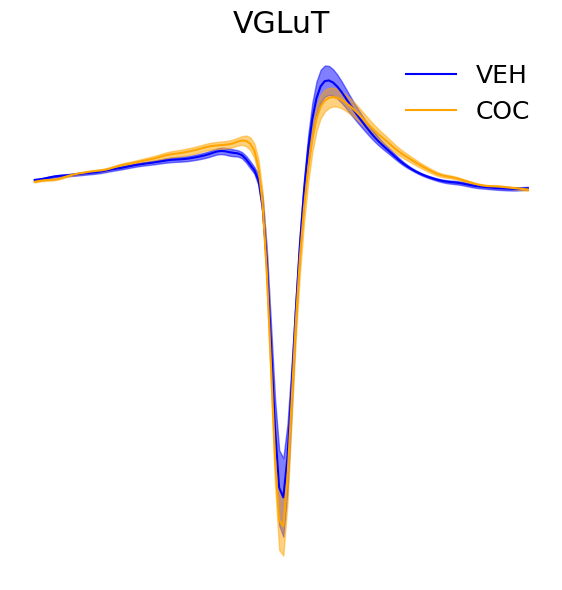

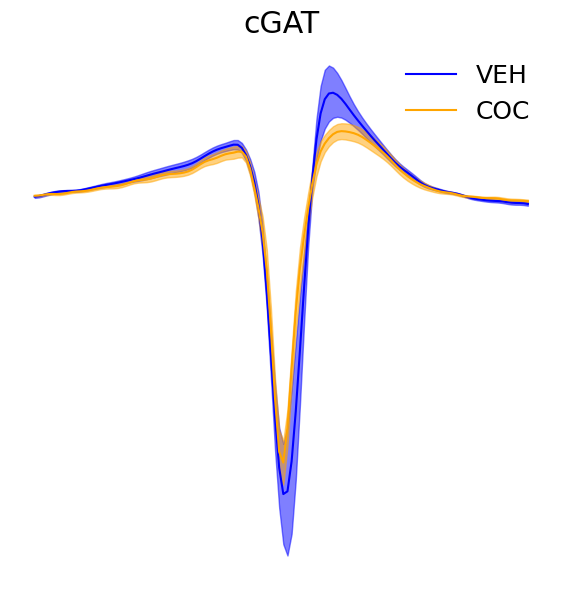

In [5]:
cocaine_file_aliases = {
    "LDT_COC31": "LDT_COCA31",
    "LDT_COC53": "LDT_COCA53",
    "LDT_COC54": "LDT_COCA54",
}
display_labels = {"CHAT": "ChAT", "Vglut": "VGLuT", "Vgat": "cGAT"}

def load_group_waveforms(units, group):
    waveforms = []
    for animal, clusters in units.items():
        file_animal = cocaine_file_aliases.get(animal, animal) if group == "COC" else animal
        for cluster in clusters:
            filename = f"Wave_{file_animal}_CLU_{int(cluster)}.npy"
            waveform_path = WAVEFORM_DIR / filename
            if not waveform_path.is_file():
                raise FileNotFoundError(f"Required waveform not found: {waveform_path}")
            waveforms.append(np.load(waveform_path))
    return np.asarray(waveforms)

all_waveforms = []
all_cell_types = []
all_groups = []

for cell_type in cocaine_units:
    vehicle_waveforms = load_group_waveforms(vehicle_units[cell_type], "VEH")
    cocaine_waveforms = load_group_waveforms(cocaine_units[cell_type], "COC")

    fig, ax = plt.subplots(figsize=(7, 7))
    for group, waveforms, color in (
        ("VEH", vehicle_waveforms, "blue"),
        ("COC", cocaine_waveforms, "orange"),
    ):
        mean_waveform = np.mean(waveforms, axis=0)
        sem_waveform = np.std(waveforms, axis=0) / np.sqrt(len(waveforms))
        ax.plot(mean_waveform, color=color, label=group)
        ax.fill_between(
            np.arange(mean_waveform.size),
            mean_waveform - sem_waveform,
            mean_waveform + sem_waveform,
            color=color,
            alpha=0.5,
        )
        all_waveforms.extend(waveforms)
        all_cell_types.extend([cell_type] * len(waveforms))
        all_groups.extend([group] * len(waveforms))

    ax.set_title(display_labels.get(cell_type, cell_type))
    ax.axis("off")
    ax.legend(frameon=False)
    plt.show()

all_waveforms = np.asarray(all_waveforms)
